In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os
from ddgs import DDGS
import re

In [2]:
df = pd.read_csv("data/laptop.csv")

# **Phân tích dữ liệu**

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1356 entries, 0 to 1355
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Tên                  1355 non-null   str  
 1   Giá                  1355 non-null   str  
 2   CPU (Bộ vi xử lý)    747 non-null    str  
 3   Ram (Bộ nhớ trong)   1303 non-null   str  
 4   Storage (Ổ cứng)     747 non-null    str  
 5   Màn hình             1297 non-null   str  
 6   Card đồ họa          1302 non-null   str  
 7   Hệ điều hành         915 non-null    str  
 8   Bàn phím             754 non-null    str  
 9   Fingerprint reader   653 non-null    str  
 10  Pin                  1182 non-null   str  
 11  Camera               743 non-null    str  
 12  Cổng kết nối vật lý  860 non-null    str  
 13  Kết nối không dây    747 non-null    str  
 14  Kích thước máy       717 non-null    str  
 15  Trọng lượng          727 non-null    str  
 16  Màu sắc              744 non-null  

In [4]:
df.head()

,Tên,Giá,CPU (Bộ vi xử lý),Ram (Bộ nhớ trong),Storage (Ổ cứng),Màn hình,Card đồ họa,Hệ điều hành,Bàn phím,Fingerprint reader,...,Tình trạng sản phẩm,Bảo hành,Hãng sản xuất,Xuất xứ,Âm thanh,Năm sản xuất,Chất liệu,Loại hàng,Tấm nền màn hình,Thời lượng pin
0,Asus Vivobook 14 X1405VA-LY623W i5 13420H RAM ...,Liên hệ,"Intel Core i5 13420H (8 nhân 12 luồng, xung nh...","16GB DDR4 3200MHz, nâng cấp được (8GB onboard ...",512GB M.2 NVMe™ PCIe® 4.0 SSD,"14"" FHD+ (1920 x 1200) IPS, màn nhám không cảm...",Intel UHD Graphics,windows 11,"Rút gọn, không có đèn Led phím",Có hỗ trợ trên touchpad,...,New 100%,24 tháng chính hãng Asus Việt Nam,Asus,China,NaN,NaN,NaN,NaN,NaN,NaN
1,GIGABYTE AERO X16 4WHN3VNC93AH Ryzen Al 9 465 ...,Liên hệ,"AMD Ryzen™ Al 9 465 (34MB cache, xung nhịp tối...","16GB DDR5 5600MHz (1 thanh), hỗ trợ nâng cấp (...","512GB SSD M.2 2242 PCIe® 4.0x4 NVMe®, hỗ trợ n...","16"" 2.5K (2560×1600) IPS, tỉ lệ 16:10, tần số ...",NVIDIA® GeForce RTX™ 5070 8GB GDDR7,Windows 11 Home,"Rút gọn, LED RGB 1 vùng",Không hỗ trợ,...,New 100%,NaN,Gigabyte,China,"Dolby Audio, loa kép 2W x2",2026,NaN,NaN,NaN,NaN
2,ASUS ExpertBook P5 P5405CSA-NZ0016W Ultra 5 22...,Liên hệ,Intel® Core™ Ultra 5 226V (8 nhân gồm 4P-core ...,16GB LPDDR5X Onboard không nâng cấp được,512GB M.2 2280 NVMe™ PCIe® 4.0 SSD,"14"" 2.5K (2560 x 1600) IPS, màn nhám, không cả...",Intel® Arc™ 130V GPU onboard,windows 11 Home,"Rút gọn, led phím trắng",CÓ hỗ trợ tích hợp trên nút nguồn,...,New 100%,24 tháng chính hãng Asus Việt Nam,Asus,China,NaN,NaN,NaN,NaN,NaN,NaN
3,ASUS TUF Gaming F16 FX608JMR-RV048W 2025 i7 14...,Liên hệ,"Intel Core i7 14650HX (16 nhân 24 luồng, xung ...","16GB DDR5 5600MHz, có thể nâng cấp tối đa 64GB...",1TB PCIe® 4.0 NVMe™ M.2 SSD,"16"" FHD+ (1920 X 1200) IPS, màn nhám chống lóa...",Intel® UHD Graphics + NVIDIA® GeForce RTX™ 506...,Windows 11 Home,"Full size với phần phím số, có đèn LED RGB 1 zone",không hỗ trợ,...,New 100%,24 tháng chính hãng Asus Việt Nam,Asus,China,"2 loa dưới mé cạnh trái phải, hỗ trợ Dolby Atm...",2025,Nhựa cứng chịu lực,NaN,NaN,NaN
4,Asus ProArt P16 H7606W Ryzen AI 9 HX 370 RAM 6...,Liên hệ,"AMD Ryzen AI 9 HX 370 (12 nhân 24 luồng, xung ...",64GB LPDDR5x 7500MHz (không hỗ trợ nâng cấp),1TB M.2 NVMe™ PCIe® 4.0 SSD,"16"" 2.8K (2880x1800) Asus Lumina OLED, tỷ lệ 1...",AMD Radeon 890M + NVidia Geforce RTX 5060 8GB ...,Windows 11 Home,"Rút gọn, có led phím",NaN,...,New 100%,12 tháng tại Trung Trần,Asus,China,"6 loa, chế tác bởi Harman Kardon, hỗ trợ Dolby...",2025,Kim loại phủ nano,NaN,NaN,NaN


In [5]:
df.describe()

,Tên,Giá,CPU (Bộ vi xử lý),Ram (Bộ nhớ trong),Storage (Ổ cứng),Màn hình,Card đồ họa,Hệ điều hành,Bàn phím,Fingerprint reader,...,Tình trạng sản phẩm,Bảo hành,Hãng sản xuất,Xuất xứ,Âm thanh,Năm sản xuất,Chất liệu,Loại hàng,Tấm nền màn hình,Thời lượng pin
count,1355,1355,747,1303,747,1297,1302,915,754,653,...,935,913,754,648,386,699,573,270,182,13
unique,1349,84,377,556,269,695,527,56,190,35,...,29,38,11,4,108,21,66,2,2,9
top,Lenovo IdeaPad Slim 5 14 2025 Ryzen 7 H 255 RA...,Liên hệ,Intel Core Ultra 9 275HX (24 nhân (gồm 8 nhân ...,8GB bus 1600GHz,512GB PCIe® NVMe™ M.2 SSD,15.6 inch Full HD 1920x1080 IPS,AMD Radeon™ 780M,Windows 11,"rút gọn, có led phím",Không hỗ trợ,...,New 100%,12 tháng tại Trung Trần,Lenovo,China,2 loa nằm ở 2 mé cạnh đáy trái phải,2025,Kim loại,Nhập khẩu,IPS,Xem trong bài viết
freq,2,1251,16,43,45,27,39,320,98,396,...,506,437,329,534,71,206,239,230,177,4


# **Xử lý dữ liệu**

## Xử lý cột Tên

In [6]:
df[df['Tên'].isna()]


,Tên,Giá,CPU (Bộ vi xử lý),Ram (Bộ nhớ trong),Storage (Ổ cứng),Màn hình,Card đồ họa,Hệ điều hành,Bàn phím,Fingerprint reader,...,Tình trạng sản phẩm,Bảo hành,Hãng sản xuất,Xuất xứ,Âm thanh,Năm sản xuất,Chất liệu,Loại hàng,Tấm nền màn hình,Thời lượng pin
578,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df = df.dropna(subset = ['Tên'])
df.info()

<class 'pandas.DataFrame'>
Index: 1355 entries, 0 to 1355
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Tên                  1355 non-null   str  
 1   Giá                  1355 non-null   str  
 2   CPU (Bộ vi xử lý)    747 non-null    str  
 3   Ram (Bộ nhớ trong)   1303 non-null   str  
 4   Storage (Ổ cứng)     747 non-null    str  
 5   Màn hình             1297 non-null   str  
 6   Card đồ họa          1302 non-null   str  
 7   Hệ điều hành         915 non-null    str  
 8   Bàn phím             754 non-null    str  
 9   Fingerprint reader   653 non-null    str  
 10  Pin                  1182 non-null   str  
 11  Camera               743 non-null    str  
 12  Cổng kết nối vật lý  860 non-null    str  
 13  Kết nối không dây    747 non-null    str  
 14  Kích thước máy       717 non-null    str  
 15  Trọng lượng          727 non-null    str  
 16  Màu sắc              744 non-null    str

## Xử lý cột Giá

In [8]:
print(df['Giá'].unique())
print("Số máy đang có giá là Liên hệ:",(df['Giá'] == "Liên hệ").sum())

<StringArray>
[     'Liên hệ',   '2.800.000đ',   '9.100.000đ',  '15.990.000đ',
  '18.190.000đ',  '31.890.000đ',  '53.990.000đ',  '27.990.000đ',
  '32.990.000đ',  '23.990.000đ',  '56.500.000đ',  '25.890.000đ',
  '52.990.000đ',  '29.290.000đ',  '26.990.000đ',  '44.490.000đ',
  '32.490.000đ',  '49.990.000đ',  '39.490.000đ',  '20.990.000đ',
  '43.490.000đ',  '34.690.000đ',  '33.890.000đ',  '24.890.000đ',
  '59.990.000đ',  '31.690.000đ',  '33.590.000đ',  '29.990.000đ',
  '30.490.000đ',  '27.890.000đ',  '25.590.000đ',  '10.900.000đ',
  '45.000.000đ',  '19.990.000đ',  '21.990.000đ',  '33.290.000đ',
  '30.990.000đ',  '73.500.000đ',  '22.890.000đ',  '43.990.000đ',
  '24.900.000đ',  '32.290.000đ',  '26.500.000đ',  '12.500.000đ',
  '30.590.000đ',  '31.900.000đ',  '30.190.000đ',  '39.500.000đ',
  '29.690.000đ',  '22.690.000đ',  '27.490.000đ',  '37.790.000đ',
  '32.690.000đ',  '69.500.000đ',  '39.690.000đ',  '23.800.000đ',
  '32.500.000đ',  '46.490.000đ',  '22.990.000đ',  '29.500.000đ',
  '25.490.0

In [9]:
# Format giá laptop
pattern_vnd = r'(\d{1,3}(?:[.,]\d{3})+)\s*(?:đ|vnd|vđ|đồng)'

# Dùng duckduckgo-search để query giá laptop vì google query có capcha chặn
def get_price(product_name):
  try:
    with DDGS() as ddgs:
      query = "Giá " + product_name
      results = list(ddgs.text(query, region="vn-vi", max_results=10))
      for item in results:
        title = item.get('title', '')
        body = item.get('body', '')
        content = f"{title} {body}"
        prices = re.findall(pattern_vnd, content, re.IGNORECASE)
        if prices:
          price = prices[0] + "đ"
          return price
  except Exception as e:
    print(e)
    return None

In [10]:
if os.path.exists("data/fill.csv"): df = pd.read_csv("data/fill.csv")

# Mỗi lượt chỉ chạy 15 lần tìm kiếm để tránh bị chặn IP
indices = df[(df['Giá'] == 'Liên hệ')].index
limit = 15
cnt = 0
for idx in indices:
  if cnt >= limit: break

  product_name = df.loc[idx, 'Tên']
  price = get_price(product_name)
  if price:
    df.at[idx, 'Giá'] = price
  else:
    df.at[idx, 'Giá'] = "Tìm thêm"
  cnt += 1
  time.sleep(random.uniform(1.0, 2.5))
df.to_csv("data/fill.csv", index=False)

In [11]:
# Tìm thêm là 1053 với lần chạy đầu tiên
print("Số máy đang có giá là Liên hệ:",(df['Giá'] == "Liên hệ").sum())
print("Số máy đang có giá là Tìm thêm:",(df['Giá']== "Tìm thêm").sum())

Số máy đang có giá là Liên hệ: 0
Số máy đang có giá là Tìm thêm: 1053


In [12]:
# Tạo file danh sách tên các máy bị thiếu giá
df_missing = df[df['Giá']== "Tìm thêm"].copy()
names = df_missing['Tên'].tolist()
with open('data/danh_sach_ten.txt', 'w', encoding='utf-8') as file:
  for name in names:
    file.write(f"{name}\n")

In [13]:
# Gán giá cho từng laptop theo index
# Check điều kiện để không ghi đè lại file sau lần chạy đầu tiên
if (df['Giá']== "Tìm thêm").sum() == 1053:
  with open('data/price.txt', 'r', encoding='utf-8') as file:
    prices = [line.strip() for line in file]
  indices = df[(df['Giá'] == "Tìm thêm")].index
  cnt = 0
  for i, idx in enumerate(indices):
    if i < len(prices):
      df.at[idx, 'Giá'] = prices[i]
      cnt+=1
    else: break
  df.to_csv("data/fill.csv", index=False)
print("Số máy đang có giá là Tìm thêm:",(df['Giá']== "Tìm thêm").sum())

Số máy đang có giá là Tìm thêm: 1018


In [14]:
# Chuẩn hóa giá laptop về dạng float, đơn vị là nghìn đồng
df['Giá'] = df['Giá'].str.replace('đ', '')
df['Giá'] = df['Giá'].str.replace('.', '')
df['Giá'] = df['Giá'].str.replace(',', '')
df['Giá'] = pd.to_numeric(df['Giá'], errors='coerce')
df['Giá'] = df['Giá'] / 1000
print("Số máy đang có giá:",df['Giá'].notna().sum())

Số máy đang có giá: 337


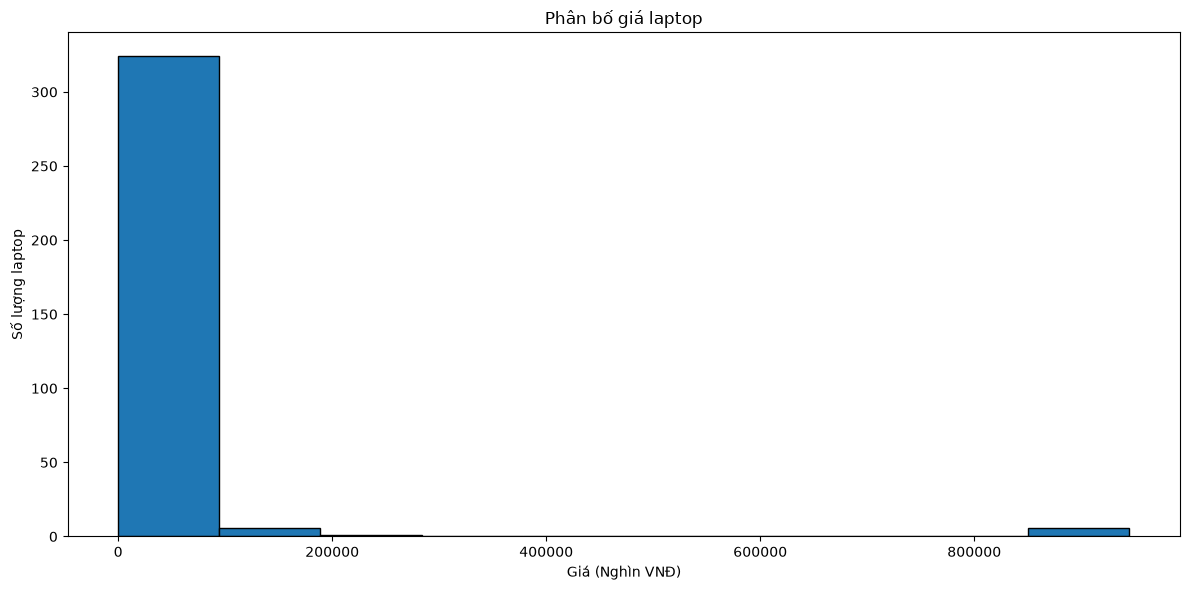

In [15]:
plt.figure(figsize=(12, 6))
plt.hist(df['Giá'], edgecolor='black')
plt.title("Phân bố giá laptop")
plt.xlabel("Giá (Nghìn VNĐ)")
plt.ylabel("Số lượng laptop")
plt.tight_layout()
plt.show()

In [16]:
# Lọc giá laptop, lấy giá từ hơn 3 triệu -> 160 triệu
df['Giá'].describe()
df = df[(df['Giá'] > 3000) & (df['Giá'] <= 160000)]
df.info()

<class 'pandas.DataFrame'>
Index: 308 entries, 0 to 1303
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tên                  308 non-null    str    
 1   Giá                  308 non-null    float64
 2   CPU (Bộ vi xử lý)    201 non-null    str    
 3   Ram (Bộ nhớ trong)   303 non-null    str    
 4   Storage (Ổ cứng)     201 non-null    str    
 5   Màn hình             298 non-null    str    
 6   Card đồ họa          303 non-null    str    
 7   Hệ điều hành         235 non-null    str    
 8   Bàn phím             200 non-null    str    
 9   Fingerprint reader   178 non-null    str    
 10  Pin                  277 non-null    str    
 11  Camera               198 non-null    str    
 12  Cổng kết nối vật lý  208 non-null    str    
 13  Kết nối không dây    199 non-null    str    
 14  Kích thước máy       188 non-null    str    
 15  Trọng lượng          193 non-null    str    
 16  Màu s

## Xử lý cột CPU

In [17]:
# Hàm lấy series cpu của laptop
def get_cpu_series(cpu_str):
  if pd.isna(cpu_str):
    return "Unknown"
  cpu_str = str(cpu_str).upper()

  # Tìm cpu dạng M1 -> M5
  found = re.search(r'\b(M[1-5])\b', cpu_str)
  if found:
    return f"Apple {found.group(1)}"

  # Tìm cpu của hãng AMD
  if "AMD" in cpu_str or "RYZEN" in cpu_str or re.search(r'\bR[3579]\b', cpu_str):
    # Format Ryzen 9, Ryzen AI 9, R9, Ryzen AI™ 9,...
    if re.search(r'RYZEN[\s™®]*(?:AI[\s™®]*|AL[\s™®]*)?9|\bR9\b|MAX\+\s*395', cpu_str):
      return "AMD Ryzen 9"
    elif re.search(r'RYZEN[\s™®]*(?:AI[\s™®]*|AL[\s™®]*)?7|\bR7\b', cpu_str):
      return "AMD Ryzen 7"
    elif re.search(r'RYZEN[\s™®]*(?:AI[\s™®]*|AL[\s™®]*)?5|\bR5\b', cpu_str):
      return "AMD Ryzen 5"
    elif re.search(r'RYZEN[\s™®]*(?:AI[\s™®]*|AL[\s™®]*)?3|\bR3\b', cpu_str):
      return "AMD Ryzen 3"
    return "AMD Other"

  if re.search(r'\bI9\b|CORE[\s™®]*(?:ULTRA[\s™®]*X?)?9|ULTRA[\s™®]*X?9', cpu_str):
    return "Intel Core i9 / Ultra 9"
  elif re.search(r'\bI7\b|CORE[\s™®]*(?:ULTRA[\s™®]*X?)?7|ULTRA[\s™®]*X?7', cpu_str):
    return "Intel Core i7 / Ultra 7"
  elif re.search(r'\bI5\b|CORE[\s™®]*(?:ULTRA[\s™®]*X?)?5|ULTRA[\s™®]*X?5', cpu_str):
    return "Intel Core i5 / Ultra 5"
  elif re.search(r'\bI3\b|CORE[\s™®]*(?:ULTRA[\s™®]*X?)?3|ULTRA[\s™®]*X?3', cpu_str):
    return "Intel Core i3 / Ultra 3"
  elif re.search(r'CELERON|PENTIUM|\bN\d{3}\b', cpu_str):
    return "Intel Low-end"
  elif "XEON" in cpu_str:
    return "Intel Xeon"
  elif "INTEL" in cpu_str:
    return "Intel Other"

  return "Other"

# Tìm series của cpu từ cột "CPU (Bộ vi xử lý)"
df['CPU_Series'] = df['CPU (Bộ vi xử lý)'].apply(get_cpu_series)
# Tìm series của cpu từ cột "Tên" đối với các dòng không tìm được cụ thể
condition = df['CPU_Series'].isin(['Other', 'Unknown', 'Intel Other', 'AMD Other'])
df.loc[condition, 'CPU_Series'] = df.loc[condition, 'Tên'].apply(get_cpu_series)

print(df['CPU_Series'].value_counts())

CPU_Series
Intel Core i7 / Ultra 7    127
Intel Core i5 / Ultra 5     83
AMD Ryzen 7                 28
Intel Core i9 / Ultra 9     17
AMD Ryzen 9                 14
AMD Ryzen 5                  8
Other                        7
Intel Xeon                   6
Apple M4                     4
Apple M2                     3
Apple M1                     3
AMD Other                    3
Intel Core i3 / Ultra 3      2
AMD Ryzen 3                  2
Intel Low-end                1
Name: count, dtype: int64


In [18]:
# Check cửa hàng thì thực tế không có AMD Ryzen 3 nên xử lý lại dữ liệu
df[df['CPU_Series'] == 'AMD Ryzen 3']

,Tên,Giá,CPU (Bộ vi xử lý),Ram (Bộ nhớ trong),Storage (Ổ cứng),Màn hình,Card đồ họa,Hệ điều hành,Bàn phím,Fingerprint reader,...,Tình trạng sản phẩm,Bảo hành,Hãng sản xuất,Xuất xứ,Âm thanh,Năm sản xuất,Chất liệu,Loại hàng,Tấm nền màn hình,CPU_Series
1298,Alienware 15 R3 i7 6700HQ FullHD VGA GTX 1060 6GB,15279.0,NaN,16GB DDR4 at 2400MHz,NaN,15.6 inch FHD (1920 x 1080) IPS Anti-Glare 300...,NVIDIA® GeForce® GTX 1060 with 6GB GDDR5,Windows 10,NaN,NaN,...,NaN,Bảo hành chính hãng 24 tháng,NaN,NaN,NaN,NaN,NaN,NaN,IPS,AMD Ryzen 3
1299,Alienware 15 R3 i7 6700HQ FullHD VGA Nvidia GT...,15279.0,NaN,8GB DDR4 at 2400MHz,NaN,15.6 inch FHD (1920 x 1080) IPS Anti-Glare 300...,NVIDIA® GeForce® GTX 1060 with 6GB GDDR5,Windows 10,NaN,NaN,...,NaN,Bảo hành chính hãng 24 tháng,NaN,NaN,NaN,NaN,NaN,NaN,IPS,AMD Ryzen 3


In [19]:
condition = df['Tên'].str.contains('Alienware 15 R3')
df.loc[condition, 'CPU_Series'] = 'Intel Core i7 / Ultra 7'
display(df[condition][['Tên', 'CPU_Series']])

,Tên,CPU_Series
1298,Alienware 15 R3 i7 6700HQ FullHD VGA GTX 1060 6GB,Intel Core i7 / Ultra 7
1299,Alienware 15 R3 i7 6700HQ FullHD VGA Nvidia GT...,Intel Core i7 / Ultra 7


In [20]:
# Xử lý các dòng không tìm được series của cpu
df[df['CPU_Series'] == 'Other']['Tên']

508           Dell Precision M6700 Workstation Red Covet
593        Macbook Air 11inch MJVM2 New 100% Nguyên Seal
645    Macbook Pro Retina 13.3inch MGX72 Apple Care 0...
667        Dell Precision M4600 Full HD IPS Quadro 2000M
711                MSI GT83VR 7RF Titan SLI Dual GTX1080
738                          MSI Gaming GP62 6QE 1221XVN
746                          MSI Gaming GL62 6QE-1223XVN
Name: Tên, dtype: str

In [21]:
indices = [593, 645, 746]
df.loc[indices, 'CPU_Series'] = "Intel Core i5 / Ultra 5"
indices = [508, 667, 711, 738]
df.loc[indices, 'CPU_Series'] = "Intel Core i7 / Ultra 7"
print(df['CPU_Series'].value_counts())

CPU_Series
Intel Core i7 / Ultra 7    133
Intel Core i5 / Ultra 5     86
AMD Ryzen 7                 28
Intel Core i9 / Ultra 9     17
AMD Ryzen 9                 14
AMD Ryzen 5                  8
Intel Xeon                   6
Apple M4                     4
Apple M2                     3
Apple M1                     3
AMD Other                    3
Intel Core i3 / Ultra 3      2
Intel Low-end                1
Name: count, dtype: int64


## Xử lý cột Ram

In [22]:
# Hàm lấy ra số GB ram
def get_ram(ram_str):
    if pd.isna(ram_str):
        return np.nan
    # search format ? gb
    found = re.search(r'(\d+)\s*GB', str(ram_str), re.IGNORECASE)
    return int(found.group(1)) if found else np.nan

# Lấy ram từ cột "Ram (Bộ nhớ trong)"
df['RAM_GB'] = df['Ram (Bộ nhớ trong)'].apply(get_ram)
# Lấy ram từ cột "Tên" với các dòng bị thiếu
df['RAM_GB'] = df['RAM_GB'].fillna(df['Tên'].apply(get_ram))
print(df['RAM_GB'].value_counts())

RAM_GB
16.0    132
8.0      94
32.0     53
4.0      13
64.0      7
24.0      4
96.0      2
12.0      2
Name: count, dtype: int64


In [23]:
# Fill median vào các dòng bị thiếu
df['RAM_GB'] = df['RAM_GB'].fillna(df['RAM_GB'].median())
df['RAM_GB'].count()

np.int64(308)

## Xử lý cột Storage

In [24]:
# Hàm lấy storage
def get_storage(storage_str):
  if pd.isna(storage_str):
    return np.nan
  storage_str = str(storage_str).upper()
  # search format 3-4 chữ số và có GB hoặc chỉ có G
  found = re.search(r'(\d{3,4})\s*G?B', storage_str)
  if found:
    return int(found.group(1))
  # search format TB
  found = re.search(r'(\d+)\s*TB', storage_str)
  if found:
    return int(found.group(1)) * 1024
  return np.nan

# Lấy storage từ cột "Storage (Ổ cứng)"
df['Storage_GB'] = df['Storage (Ổ cứng)'].apply(get_storage)
# Lấy storage từ cột "Tên" với các dòng bị thiếu
df['Storage_GB'] = df['Storage_GB'].fillna(df['Tên'].apply(get_storage))
print(df['Storage_GB'].value_counts())

Storage_GB
512.0     136
1024.0     57
256.0      46
2048.0      6
500.0       3
128.0       3
180.0       2
240.0       2
711.0       1
Name: count, dtype: int64


In [25]:
# Check data có 711 GB
df[df['Storage_GB'] == 711]['Tên']

605    Macbook Air 11 inch Early 2014 MD711B CPU i5 4...
Name: Tên, dtype: str

In [26]:
df.loc[df['Storage_GB'] == 711, 'Storage_GB'] = 128

In [27]:
# Fill median vào các dòng bị thiếu
df['Storage_GB'] = df['Storage_GB'].fillna(df['Storage_GB'].median())
df['Storage_GB'].count()

np.int64(308)

## Xử lý cột GPU

In [28]:
# Hàm lấy series của GPU
def get_gpu_series(gpu_str):
  if pd.isna(gpu_str):
    return "Unknown"
  gpu_str = str(gpu_str).upper()
  
  # search format RTX A????
  found = re.search(r'RTX[\s™®]*A(\d{4})', gpu_str)
  if found:
    return f"NVIDIA RTX A{found.group(1)}"

  found = re.search(r'RTX[\s™®]*(\d{4})', gpu_str)
  if found:
    return f"NVIDIA RTX {found.group(1)}"

  found = re.search(r'GTX[\s™®]*(\d{3,4})', gpu_str)
  if found:
    return f"NVIDIA GTX {found.group(1)}"

  if "QUADRO" in gpu_str or re.search(r'\b(?:K|M|P|T)\d{3,4}M?\b', gpu_str):
      return "NVIDIA Quadro"
  if "MX" in gpu_str and ("NVIDIA" in gpu_str or "GEFORCE" in gpu_str or re.search(r'MX\d{3}', gpu_str)):
      return "NVIDIA MX"
  if "NVIDIA" in gpu_str or "GEFORCE" in gpu_str:
      return "NVIDIA Other"

  found = re.search(r'RADEON[\s™®]*(\d{3}M)', gpu_str)
  if found:
      return f"AMD Radeon {found.group(1)}"
  elif "RADEON" in gpu_str or "AMD" in gpu_str:
      return "AMD Radeon/Onboard"

  if "APPLE" in gpu_str or re.search(r'\bM[1-5]\b', gpu_str):
      return "Apple GPU"

  if "IRIS" in gpu_str or "XE GRAPHICS" in gpu_str:
      return "Intel Iris Xe"
  elif "ARC" in gpu_str:
      return "Intel Arc"
  elif "UHD" in gpu_str or "HD GRAPHICS" in gpu_str or "INTEL HD" in gpu_str or "INTEL® GRAPHICS" in gpu_str or "INTEL GRAPHICS" in gpu_str:
      return "Intel UHD/HD"
  elif "INTEL" in gpu_str:
      return "Intel Other"

  return "Other"

# Tìm gpu từ cột "Card đồ họa"
df['GPU_Series'] = df['Card đồ họa'].apply(get_gpu_series)
# Tìm series của gpu từ cột "Tên" đối với các dòng không tìm được cụ thể
condition = df['GPU_Series'].isin(["Unknown", "Other", "NVIDIA Other", "Intel Other"])
df.loc[condition, 'GPU_Series'] = df.loc[condition, 'Tên'].apply(get_gpu_series)
print(df['GPU_Series'].value_counts())

GPU_Series
Intel UHD/HD          75
NVIDIA Quadro         34
NVIDIA RTX 5060       26
Intel Arc             22
Intel Iris Xe         14
NVIDIA RTX 3050       12
Other                 12
AMD Radeon/Onboard    12
Apple GPU              9
NVIDIA RTX 5050        9
AMD Radeon 780M        9
NVIDIA RTX 5070        8
NVIDIA RTX A2000       7
NVIDIA MX              6
NVIDIA RTX A1000       5
NVIDIA RTX 4050        4
NVIDIA GTX 1050        4
NVIDIA RTX 2000        3
NVIDIA RTX 4060        3
NVIDIA GTX 960         3
NVIDIA RTX 3060        3
AMD Radeon 880M        2
NVIDIA RTX 5080        2
NVIDIA RTX 5090        2
AMD Radeon 680M        2
NVIDIA GTX 950         2
NVIDIA GTX 1650        2
NVIDIA GTX 1060        2
NVIDIA RTX 3500        1
AMD Radeon 890M        1
AMD Radeon 660M        1
NVIDIA RTX A3000       1
Intel Other            1
NVIDIA RTX A4000       1
AMD Radeon 840M        1
NVIDIA Other           1
NVIDIA GTX 1080        1
NVIDIA RTX 2060        1
NVIDIA RTX 3080        1
NVIDIA RTX 309

## Xử lý cột Màn

In [29]:
df.info()

<class 'pandas.DataFrame'>
Index: 308 entries, 0 to 1303
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tên                  308 non-null    str    
 1   Giá                  308 non-null    float64
 2   CPU (Bộ vi xử lý)    201 non-null    str    
 3   Ram (Bộ nhớ trong)   303 non-null    str    
 4   Storage (Ổ cứng)     201 non-null    str    
 5   Màn hình             298 non-null    str    
 6   Card đồ họa          303 non-null    str    
 7   Hệ điều hành         235 non-null    str    
 8   Bàn phím             200 non-null    str    
 9   Fingerprint reader   178 non-null    str    
 10  Pin                  277 non-null    str    
 11  Camera               198 non-null    str    
 12  Cổng kết nối vật lý  208 non-null    str    
 13  Kết nối không dây    199 non-null    str    
 14  Kích thước máy       188 non-null    str    
 15  Trọng lượng          193 non-null    str    
 16  Màu s

In [30]:
# Hàm tìm độ phân giải của màn hình
def get_resolution(resolution_str):
  if pd.isna(resolution_str):
    return "Unknown"
  resolution_str = str(resolution_str).upper()
  # Trong trường hợp tìm kiếm từ cột Tên thì bỏ đi INTEL HD, INTEL GRAPHICS HD,...
  resolution_str = re.sub(r'INTEL®?\s*HD|HD\s*GRAPHICS|HD\s*\d{4}', '', resolution_str)

  if re.search(r'\b4K\b|\b4\.5K\b|\bUHD\+?\b|ULTRA\s*HD|3840\s*[X×*]|4480\s*[X×*]', resolution_str):
    return "4K / UHD"
  if re.search(r'\b3K\b|\b3\.2K\b|\b2\.8K\b|2880\s*[X×*]|3000\s*[X×*]|3072\s*[X×*]|3200\s*[X×*]|QHD\+', resolution_str):
    return "2.8K / 3K"
  if re.search(r'\b2K\b|\b2\.5K\+?\b|\bQHD\b|\bWQHD\b|\bWQXGA\b|2560\s*[X×*]|2240\s*[X×*]|LIQUID\s*RETINA|RETINA', resolution_str):
    return "2K / 2.5K (QHD)"
  if re.search(r'FHD\+|\bWUXGA\b|1920\s*[X×*]\s*1200', resolution_str):
    return "FHD+ (1920x1200)"
  if re.search(r'\bFHD\b|FULL\s*HD|1920\s*[X×*]\s*1080', resolution_str):
    return "FHD (1920x1080)"
  if re.search(r'HD\+|\bHD\b|1600\s*[X×*]\s*900|1366\s*(?:[X×*]|BY)\s*768', resolution_str):
    return "HD / HD+"
  return "Unknown"

In [31]:
# Lấy độ phân giải từ cột "Màn hình"
df['Resolution'] = df['Màn hình'].apply(get_resolution)
# Lấy độ phân giải từ cột "Tên" với các hàng không tìm được
condition = (df['Resolution'] == "Unknown")
df.loc[condition, 'Resolution'] = df.loc[condition, 'Tên'].apply(get_resolution)

print(df['Resolution'].value_counts())

Resolution
FHD (1920x1080)     110
FHD+ (1920x1200)     68
2K / 2.5K (QHD)      56
2.8K / 3K            43
HD / HD+             13
4K / UHD             11
Unknown               7
Name: count, dtype: int64


In [32]:
# Xử lý data không tìm được
display(df[df['Resolution'] == 'Unknown'][['Tên', 'Màn hình']])

,Tên,Màn hình
60,Mini PC Gigabyte BRIX GB-BRU7-255H Core Ultra ...,NaN
61,Mini PC Gigabyte BRIX GB-BTIP-N250 Intel N250,NaN
62,Mini PC Gigabyte BRIX GB-BRU5-225H Core Ultra ...,NaN
593,Macbook Air 11inch MJVM2 New 100% Nguyên Seal,11.6-inch (diagonal) high-resolution LED-backl...
608,HP Z440 Workstation Xeon E5-1603 NVIDIA Quadro...,NaN
647,Dell Precision M6700 Workstation CPU i7-3940XM,NaN
1174,Alienware Aurora R13 i9-12900KF 32GB SSD 2TB N...,NaN


In [33]:
df.at[593, 'Resolution'] = 'HD / HD+'
df.at[647, 'Resolution'] = 'FHD (1920x1080)'
indices = [60, 61, 62, 608, 1174]
df.loc[indices, 'Resolution'] = "No Screen"
print(df['Resolution'].value_counts())

Resolution
FHD (1920x1080)     111
FHD+ (1920x1200)     68
2K / 2.5K (QHD)      56
2.8K / 3K            43
HD / HD+             14
4K / UHD             11
No Screen             5
Name: count, dtype: int64


In [34]:
# Tìm tần số quét của màn
def get_refresh_rate(hz_str):
  if pd.isna(hz_str):
    return np.nan
  found = re.search(r'(\d{2,3})\s*HZ', str(hz_str).upper())
  if found:
    hz = float(found.group(1))
    if 60 <= hz <= 360:
      return hz
  return np.nan

In [35]:
# Tìm tần số quét từ cột "Màn hình"
df['HZ'] = df['Màn hình'].apply(get_refresh_rate)
# Tìm tần số quét từ cột "Tên" với các hàng không tìm được
df['HZ'] = df['HZ'].fillna(df['Tên'].apply(get_refresh_rate))
print(df['HZ'].value_counts())

HZ
60.0     58
120.0    37
165.0    30
144.0    20
240.0    13
180.0     5
100.0     3
300.0     3
360.0     1
Name: count, dtype: int64


In [36]:
# Tần số quét mặc định của laptop là 60
df['HZ'] = df['HZ'].fillna(60.0)

## Xử lý cột Brand

In [37]:
# Hàm tìm hãng của laptop
def get_brand(brand_str):
  if pd.isna(brand_str):
    return "Unknown"
  brand_str = str(brand_str).upper()

  if "LENOVO" in brand_str or "LEGION" in brand_str or "THINKPAD" in brand_str:
    return "Lenovo"

  if "ASUS" in brand_str:
    return "Asus"

  if "DELL" in brand_str or "ALIENWARE" in brand_str:
    return "Dell"

  if "APPLE" in brand_str or "MACBOOK" in brand_str:
    return "Apple"

  if "GIGABYTE" in brand_str:
    return "Gigabyte"

  if "HP" in brand_str:
    return "HP"

  if "ACER" in brand_str:
    return "Acer"

  if "LECOO" in brand_str:
    return "Lenovo/Lecoo"

  if "MSI" in brand_str:
    return "MSI"

  return "Other"

In [38]:
df['Hãng sản xuất'] = df['Hãng sản xuất'].fillna(df['Tên'].apply(get_brand))
print(df['Hãng sản xuất'].value_counts())

Hãng sản xuất
Lenovo          111
Dell             91
Asus             53
Apple            15
HP               15
Gigabyte         10
Acer              5
Lenovo/Lecoo      3
MSI               3
Lenov             1
Other             1
Name: count, dtype: int64


In [39]:
df[df['Hãng sản xuất'] == "Lenov"]

,Tên,Giá,CPU (Bộ vi xử lý),Ram (Bộ nhớ trong),Storage (Ổ cứng),Màn hình,Card đồ họa,Hệ điều hành,Bàn phím,Fingerprint reader,...,Năm sản xuất,Chất liệu,Loại hàng,Tấm nền màn hình,CPU_Series,RAM_GB,Storage_GB,GPU_Series,Resolution,HZ
100,ThinkPad X14 2026 Ultra X7-358H RAM 32GB SSD 1...,59990.0,"Intel Core Ultra X7 358H (16 nhân, 16 luồng, ...","RAM 32GB DDR5x 8533MT/s, không hỗ trợ nâng cấp",1TB M.2 2242 PCIe Gen4 SSD,"14"" 2.8K (2880x1800) OLED, không cảm ứng, 16:1...",Intel® Arc™ B390 GPU,Windows 11 + Office 2024 vĩnh viễn,"rút gọn, có led phím trắng",NaN,...,2026,Hợp chất CarbonxMagie,NaN,NaN,Intel Core i7 / Ultra 7,32.0,1024.0,Intel Arc,2.8K / 3K,60.0


In [40]:
df.loc[df['Hãng sản xuất'] == "Lenov", 'Hãng sản xuất'] = "Lenovo"

# Code Model

In [41]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import VotingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [42]:
# Không lấy cột "Resolution" vì
# + Máy đời cũ 4k lẫn với máy 4k đời mới, giá 2 đời rất chênh nhau
# + Label encoding cột này khi phân chia ngưỡng tạo nhóm không hợp lý
# => Overfitting, Điểm giảm
df = df[['Giá', 'CPU_Series', 'RAM_GB', 'Storage_GB', 'GPU_Series', 'Hãng sản xuất', 'HZ']].copy()
df.info()

<class 'pandas.DataFrame'>
Index: 308 entries, 0 to 1303
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Giá            308 non-null    float64
 1   CPU_Series     308 non-null    str    
 2   RAM_GB         308 non-null    float64
 3   Storage_GB     308 non-null    float64
 4   GPU_Series     308 non-null    str    
 5   Hãng sản xuất  308 non-null    str    
 6   HZ             308 non-null    float64
dtypes: float64(4), str(3)
memory usage: 27.4 KB


In [43]:
# Label Encoding các cột này
le = LabelEncoder()
category_list = ['CPU_Series', 'GPU_Series', 'Hãng sản xuất']
df[category_list] = df[category_list].apply(lambda x : le.fit_transform(x))
df.head()

,Giá,CPU_Series,RAM_GB,Storage_GB,GPU_Series,Hãng sản xuất,HZ
0,16890.0,8,16.0,512.0,11,2,60.0
1,49990.0,3,16.0,512.0,34,4,165.0
2,30990.0,8,16.0,512.0,8,2,144.0
3,39590.0,9,16.0,1024.0,33,2,165.0
4,79800.0,3,64.0,1024.0,33,2,120.0


In [44]:
X = df[['CPU_Series', 'RAM_GB', 'Storage_GB', 'GPU_Series', 'Hãng sản xuất', 'HZ']]
y = df['Giá']
# Train 80%, Test 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)


model_xgb = XGBRegressor(random_state=42, n_estimators=100)
model_lgbm = LGBMRegressor(random_state=42, n_estimators=100, verbose=-1) #verbose = -1 để tắt thông báo
base_models = [('xgb', model_xgb), ('lgbm', model_lgbm)]
ensemble_voting = VotingRegressor(estimators=base_models)
models = {
    "XGBoost": model_xgb,
    "LightGBM": model_lgbm,
    "Ensemble Voting": ensemble_voting
}

results = []
for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)

  r2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  rmse = root_mean_squared_error(y_test, y_pred)

  results.append({
    "Model": name,
    "R2 Score": round(r2, 4),
    "MAE": round(mae, 1),
    "RMSE": round(rmse, 1)
  })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

          Model  R2 Score    MAE    RMSE
        XGBoost    0.7282 7671.6 11420.7
       LightGBM    0.7549 7748.4 10844.4
Ensemble Voting    0.7784 7187.4 10312.2


## Tối ưu tham số

In [45]:
# Quá trình này tốn khoảng 9p

xgb_param = {
    'n_estimators': [100, 150, 200, 250],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'reg_lambda': [0.5, 1.0, 2.0, 5.0],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Vét cạn tìm tổ hợp tham số
grid_xgb = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=xgb_param,
    scoring='r2',
    cv=5,
    n_jobs=-1
)
grid_xgb.fit(X_train, y_train)
tuned_xgb = grid_xgb.best_estimator_
print("Tham số tốt nhất của XGBoost:", grid_xgb.best_params_)

lgbm_param = {
    'n_estimators': [100, 150, 200, 250],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [-1, 4, 5, 6],
    'min_child_samples': [5, 10, 15, 20],
    'reg_lambda': [1.0, 2.0, 5.0],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_lgbm = GridSearchCV(
    estimator=LGBMRegressor(random_state=42, verbose=-1),
    param_grid=lgbm_param,
    scoring='r2',
    cv=5,
    n_jobs=-1
)
grid_lgbm.fit(X_train, y_train)
tuned_lgbm = grid_lgbm.best_estimator_
print("Tham số tốt nhất của LightGBM:", grid_lgbm.best_params_)

Tham số tốt nhất của XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 150, 'reg_lambda': 5.0, 'subsample': 1.0}
Tham số tốt nhất của LightGBM: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'min_child_samples': 5, 'n_estimators': 150, 'reg_lambda': 5.0, 'subsample': 0.8}


In [46]:
ensemble_voting = VotingRegressor(estimators=[('xgb', tuned_xgb), ('lgbm', tuned_lgbm)])

tuned_models = {
    "XGBoost": tuned_xgb,
    "LightGBM": tuned_lgbm,
    "Ensemble Voting": ensemble_voting
}

results = []
for name, model in tuned_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": round(r2_score(y_test, y_pred), 4),
        "MAE": round(mean_absolute_error(y_test, y_pred), 1),
        "RMSE": round(root_mean_squared_error(y_test, y_pred), 1)
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

          Model  R2 Score    MAE   RMSE
        XGBoost    0.8087 6650.0 9579.9
       LightGBM    0.8292 6586.4 9054.3
Ensemble Voting    0.8246 6507.5 9175.0
